# Week 12 — Ultrasound point spread function: why a swept scan line gives a teardrop

Every imaging system blurs. If $I$ is the true image (the tissue reflectivity we would like to see) and the
system has a convolution kernel $H$ (its **point spread function**, PSF), the measured, digitized image is

$$J = I * H .$$

This is the same convolution model we used in the filtering and deconvolution weeks. What is new for
ultrasound is the *shape* of $H$. A B-mode image is built by **sweeping a narrow beam through a sector**:
the transducer fires along one scan line, listens for echoes, then rotates (mechanically or by electronic
steering) a fraction of a degree and repeats. The PSF of a single point reflector in the final picture is not a
round Gaussian blob. It looks like a **teardrop** (a wide leading edge with a tail that tapers with
depth), and its orientation rotates with the scan line as it swings.

In this notebook we build a small ultrasound simulator and show where the teardrop comes from:

1. set up the **sector scan geometry** (scan lines indexed by angle $\theta$ and range $r$);
2. model the **beam and pulse** as a simple kernel $H$ in acquisition coordinates $(r,\theta)$;
3. **scan-convert** to the Cartesian display $(x,y)$ and look at the impulse response (the PSF);
4. blur a **phantom** to see what $J = I * H$ does to a realistic scene;
5. **measure** axial and lateral resolution versus depth.

## 1. Sector scan geometry

The transducer sits at the apex of the sector (top of the image). Each scan line $k$ points in direction
$\theta_k$; a point on that line at range $r$ (set by the echo's round-trip time, $r = c\,t/2$) maps to the display
position

$$x = r\sin\theta, \qquad y = r\cos\theta .$$

The scanner stores data in a **polar array** $(\theta_k, r)$: one row per scan line, one column per range
sample. Displaying it requires **scan conversion**, an interpolation from $(\theta, r)$ onto a Cartesian pixel grid.

361 scan lines x 1000 range samples per line


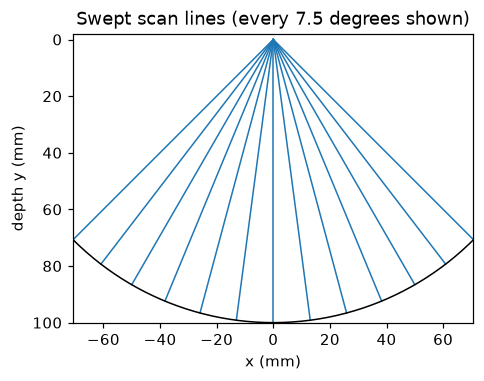

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(0)

# --- sector (swept) scan geometry: apex at the top, scan lines fan out ---
R_MAX      = 100.0                  # mm, maximum imaging depth
HALF_ANGLE = np.deg2rad(45)         # the sector spans +/- 45 degrees
dr  = 0.1                           # mm between samples along a scan line
dth = np.deg2rad(0.25)              # angle between neighbouring scan lines
r  = np.arange(0, R_MAX, dr)                          # range axis (columns)
th = np.arange(-HALF_ANGLE, HALF_ANGLE + dth, dth)    # one angle per scan line (rows)
print(f"{len(th)} scan lines x {len(r)} range samples per line")

# --- Cartesian display grid ---
PIX = 0.25                                            # mm per display pixel
xs = np.arange(-R_MAX * np.sin(HALF_ANGLE), R_MAX * np.sin(HALF_ANGLE), PIX)
ys = np.arange(0, R_MAX, PIX)
X, Y = np.meshgrid(xs, ys)
R_img, TH_img = np.hypot(X, Y), np.arctan2(X, Y)      # polar coordinates of every display pixel
inside = (R_img < R_MAX) & (np.abs(TH_img) <= HALF_ANGLE)
EXTENT = [xs[0] - PIX / 2, xs[-1] + PIX / 2, ys[-1] + PIX / 2, ys[0] - PIX / 2]


def scan_convert(polar):
    # (theta, r) array -> Cartesian image (NaN outside the sector)
    coords = [(TH_img + HALF_ANGLE) / dth, R_img / dr]
    img = ndi.map_coordinates(polar, coords, order=1, mode="constant")
    return np.where(inside, img, np.nan)


def place(points):
    # Put point scatterers given as (x_mm, y_mm, amplitude) into a polar array
    polar = np.zeros((len(th), len(r)))
    for x, y, a in points:
        rr, tt = np.hypot(x, y), np.arctan2(x, y)
        assert abs(tt) <= HALF_ANGLE and rr < R_MAX, "scatterer outside the sector"
        polar[int(round((tt + HALF_ANGLE) / dth)), int(round(rr / dr))] += a
    return polar


# Draw a few of the scan lines to visualise the sweep
fig, ax = plt.subplots(figsize=(4.5, 4.2))
for t in np.deg2rad(np.arange(-45, 46, 7.5)):
    ax.plot([0, R_MAX * np.sin(t)], [0, R_MAX * np.cos(t)], color="tab:blue", lw=1)
arc = np.linspace(-HALF_ANGLE, HALF_ANGLE, 200)
ax.plot(R_MAX * np.sin(arc), R_MAX * np.cos(arc), "k", lw=1)
ax.set_xlim(xs[0], xs[-1]); ax.set_ylim(R_MAX, -2); ax.set_aspect("equal")
ax.set_xlabel("x (mm)"); ax.set_ylabel("depth y (mm)")
ax.set_title("Swept scan lines (every 7.5 degrees shown)")
plt.tight_layout(); plt.show()

## 2. The beam and pulse as a kernel $H$

For one scan line the echo from a point reflector is shaped by two independent effects:

- **Axial (along the line, range $r$).** The transmitted pulse is short but not instantaneous. A real transducer
  rings: a sharp onset followed by a decaying tail. Along range, $H$ is therefore a short, one-sided kernel
  (we use a Gaussian-smoothed exponential decay). Axial resolution is set by the pulse length.
- **Lateral (across lines, angle $\theta$).** The beam has a finite physical width $w(r)$ that is focused:
  narrowest at the focal depth and diverging on either side,
  $w(r)=\sqrt{w_0^2 + \big(s\,(r-r_f)\big)^2}$. A point is therefore seen by every neighbouring scan line whose beam
  covers it. Because scan lines are indexed by *angle*, the width in the data is
  $\sigma_\theta(r) \approx \dfrac{w(r)/2.355}{r}$ radians, and the same physical beam width subtends a
  **smaller and smaller angle as $r$ grows**.

In acquisition coordinates $(r,\theta)$ this is just a separable blur: a 1-D axial kernel along each line and a
Gaussian across lines. We apply it row by row in range.

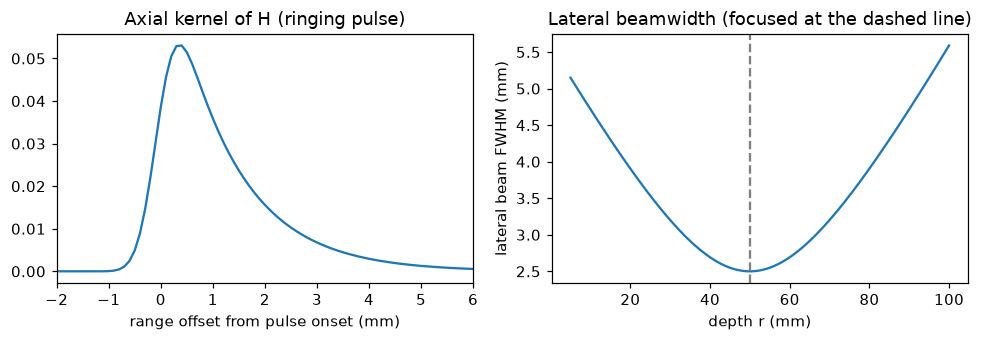

In [2]:
SIG_AX = 0.3                             # mm, Gaussian smoothing of the pulse
TAIL   = 1.2                             # mm, decay length of the ringing tail
W0, FOCUS, SPREAD = 2.5, 50.0, 0.10      # beam FWHM at focus (mm), focal depth (mm), divergence (mm/mm)


def beam_fwhm(rr):
    # Lateral beam width (FWHM, mm) vs depth: narrowest at the focus
    return np.sqrt(W0 ** 2 + (SPREAD * (rr - FOCUS)) ** 2)


def axial_kernel():
    # One-sided ringing pulse: exponential decay smoothed by a Gaussian.
    # Array index L corresponds to t = 0 (the pulse onset); later times are deeper.
    t = np.arange(0, 6 * TAIL, dr)
    g = np.exp(-0.5 * (np.arange(-4 * SIG_AX, 4 * SIG_AX + dr, dr) / SIG_AX) ** 2)
    full = np.convolve(np.exp(-t / TAIL), g)
    m = len(g) // 2
    L = len(full)
    K = np.zeros(2 * L + 1)
    K[L - m : L - m + len(full)] = full
    return K / K.sum()


K_AX = axial_kernel()


def form_image(polar_reflectivity):
    # J = I * H in acquisition (r, theta) coordinates
    out = ndi.convolve1d(polar_reflectivity, K_AX, axis=1)          # axial pulse along every line
    res = np.empty_like(out)
    for j, rr in enumerate(r):                                       # lateral beam across lines
        rc = max(rr, 5.0)                                            # avoid the singular apex
        sig_theta = (beam_fwhm(rc) / 2.355) / rc                     # beam std in radians at this depth
        res[:, j] = ndi.gaussian_filter1d(out[:, j], sig_theta / dth, mode="constant")
    return res


def to_db(img, floor=-40):
    img = img / np.nanmax(img)
    return 20 * np.log10(np.maximum(img, 10 ** (floor / 20)))


fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot((np.arange(len(K_AX)) - len(K_AX) // 2) * dr, K_AX)
ax[0].set_xlim(-2, 6)
ax[0].set_xlabel("range offset from pulse onset (mm)"); ax[0].set_title("Axial kernel of H (ringing pulse)")
rr = np.linspace(5, R_MAX, 300)
ax[1].plot(rr, beam_fwhm(rr)); ax[1].axvline(FOCUS, ls="--", color="gray")
ax[1].set_xlabel("depth r (mm)"); ax[1].set_ylabel("lateral beam FWHM (mm)")
ax[1].set_title("Lateral beamwidth (focused at the dashed line)")
plt.tight_layout(); plt.show()

## 3. The point spread function

The PSF is the image of a single point: $J = I * H$ with $I=\delta$ gives $J=H$. We place point
scatterers at several depths on the central scan line, and at two off-axis positions, then form and
scan-convert the image. Amplitude is shown in **dB** (log compression), which is how scanners display echoes.

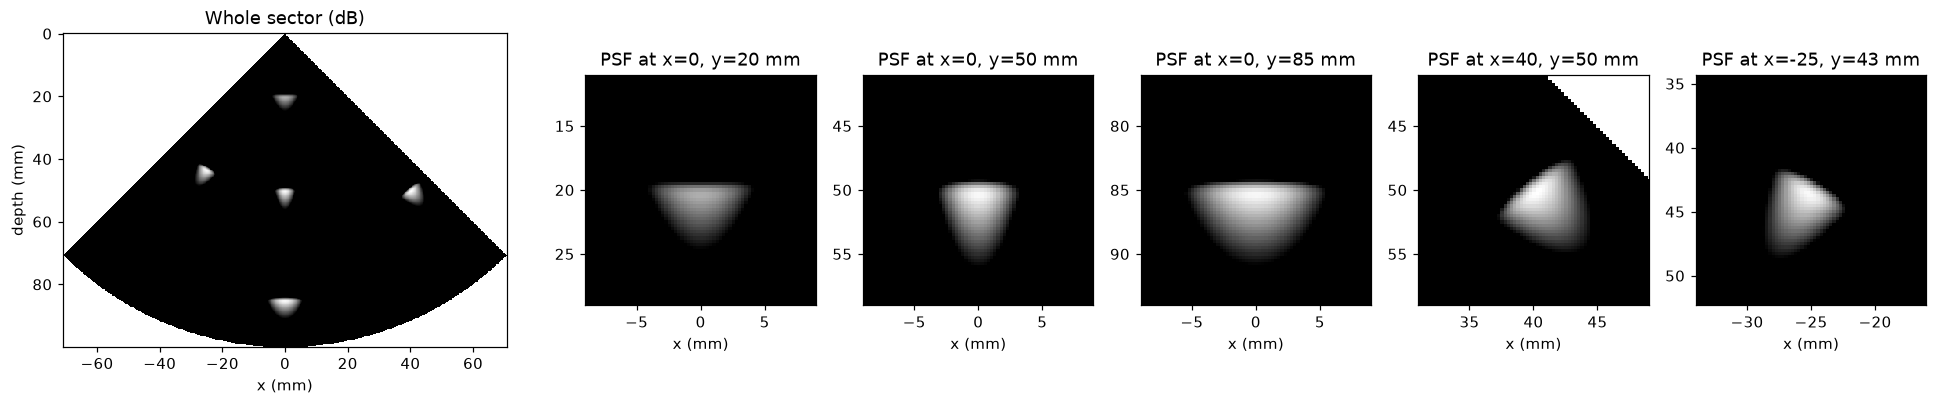

In [3]:
pts = [(0.0, 20.0), (0.0, 50.0), (0.0, 85.0), (40.0, 50.0), (-25.0, 43.3)]   # (x, y) in mm
J_pts = scan_convert(form_image(place([(x, y, 1.0) for x, y in pts])))
J_db = to_db(J_pts)

fig, axs = plt.subplots(1, 6, figsize=(18, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1, 1, 1, 1]})
axs[0].imshow(J_db, cmap="gray", extent=EXTENT, vmin=-40, vmax=0, interpolation="nearest")
axs[0].set_title("Whole sector (dB)"); axs[0].set_xlabel("x (mm)"); axs[0].set_ylabel("depth (mm)")
for a, (x, y) in zip(axs[1:], pts):
    h = 9
    a.imshow(J_db, cmap="gray", extent=EXTENT, vmin=-40, vmax=0, interpolation="nearest")
    a.set_xlim(x - h, x + h); a.set_ylim(y + h, y - h)
    a.set_title(f"PSF at x={x:.0f}, y={y:.0f} mm"); a.set_xlabel("x (mm)")
plt.tight_layout(); plt.show()

Each isolated point appears as a **teardrop**: a wide, bright leading edge at the true depth, and a tail that
tapers as it extends deeper. Two ingredients make this shape:

- the pulse **rings**, so echoes keep arriving after the first one (the tail trails *deeper*, never shallower);
- a beam of fixed physical width subtends a **smaller angle at greater depth**, so the tail, which lies at
  larger range than the leading edge, is seen by fewer neighbouring scan lines and narrows.

Compare the three on-axis points: the teardrop is widest and fuzziest away from the focal depth
(20 mm and 85 mm) and tightest near the focus (50 mm). The two off-axis points show the same teardrop
**rotated** so that it still points away from the apex: the kernel follows the swinging scan line.

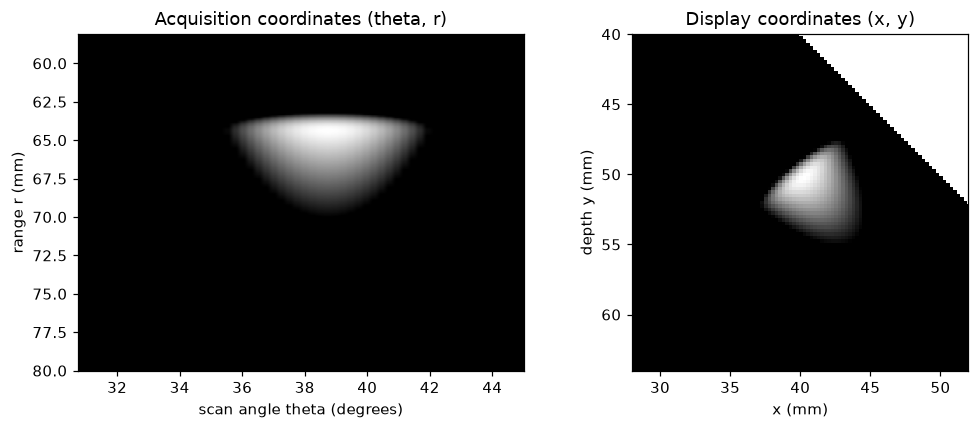

In [4]:
x0, y0 = 40.0, 50.0                                  # an off-axis point
P = form_image(place([(x0, y0, 1.0)]))
P_db = to_db(P)
r0, t0 = np.hypot(x0, y0), np.rad2deg(np.arctan2(x0, y0))

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
# acquisition coordinates: rows = scan angle, columns = range
sel_t = (np.rad2deg(th) > t0 - 8) & (np.rad2deg(th) < t0 + 8)
sel_r = (r > r0 - 6) & (r < r0 + 16)
ax[0].imshow(P_db[np.ix_(sel_t, sel_r)].T, cmap="gray", vmin=-40, vmax=0, aspect="auto",
             extent=[np.rad2deg(th[sel_t])[0], np.rad2deg(th[sel_t])[-1], r[sel_r][-1], r[sel_r][0]])
ax[0].set_xlabel("scan angle theta (degrees)"); ax[0].set_ylabel("range r (mm)")
ax[0].set_title("Acquisition coordinates (theta, r)")
# display coordinates
Jc = to_db(scan_convert(P))
ax[1].imshow(Jc, cmap="gray", extent=EXTENT, vmin=-40, vmax=0, interpolation="nearest")
ax[1].set_xlim(x0 - 12, x0 + 12); ax[1].set_ylim(y0 + 14, y0 - 10)
ax[1].set_xlabel("x (mm)"); ax[1].set_ylabel("depth y (mm)")
ax[1].set_title("Display coordinates (x, y)")
plt.tight_layout(); plt.show()

### Convolution holds in beam coordinates, not display coordinates

The left panel shows the PSF in the coordinates the scanner actually measures. The teardrop is already there,
and it is the same for every scan line: shifting the point to another scan line just moves the blob to another row
of the polar array. So along $\theta$ the model is an ordinary convolution, $J = I * H$ (it changes only slowly with
range $r$, through the beamwidth).

The right panel shows the same data after scan conversion to the $(x,y)$ display. The map
$(r,\theta)\mapsto(x,y)$ is a *warp*: it fans the scan lines out, **rotates the kernel by the local scan angle**, and
stretches it laterally by a factor proportional to $r$. In display coordinates the PSF therefore **depends on position
and orientation**: $J(x,y) = \int I(x',y')\,H(x,y;x',y')\,dx'dy'$ with a kernel that changes from place to place
(*shift-variant*). The sweep is what ties the teardrop's orientation to the scan angle, so a picture of
teardrops all pointing away from the apex is the signature of a swept-beam system.

## 4. Blurring a scene: $J = I * H$

Now use a more realistic reflectivity map $I$: bright wire targets at different depths (like a resolution
test phantom), a vessel wall (bright ring) with an echo-free lumen, and weak random tissue scatterers.
We apply the same $H$. The wires turn into teardrops, and the vessel wall and tissue texture are blurred by
a depth-dependent amount.

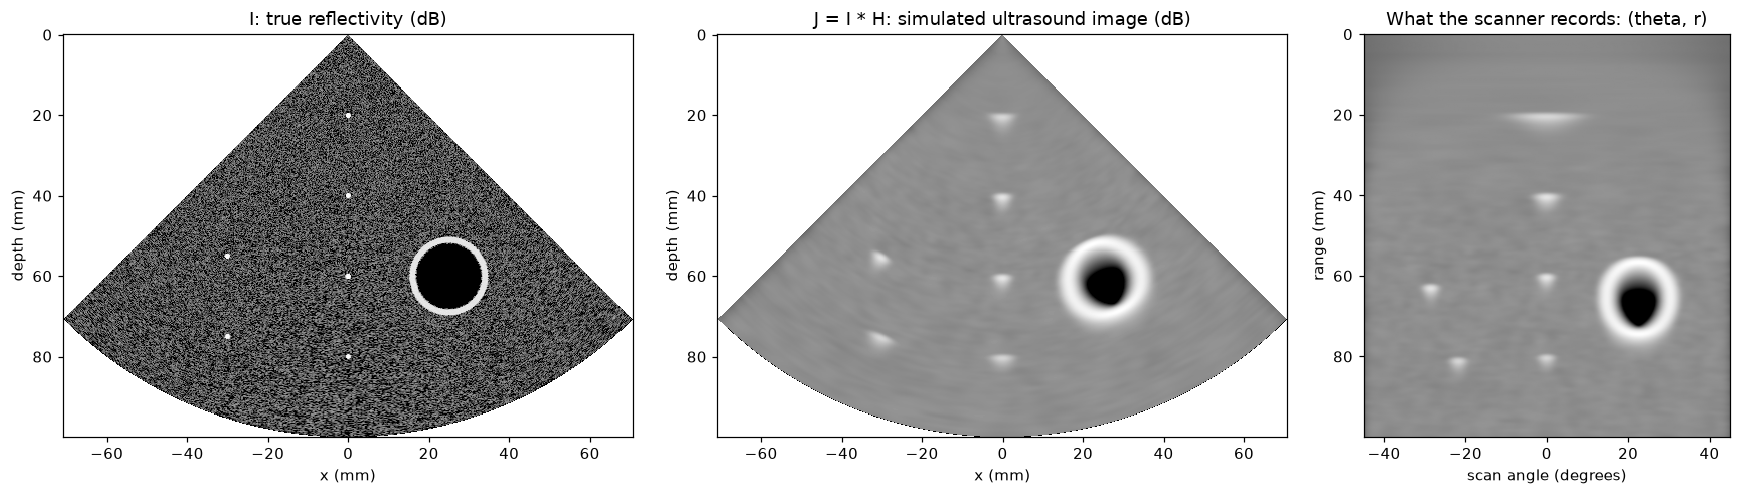

In [5]:
TH_g, R_g = np.meshgrid(th, r, indexing="ij")
Xg, Yg = R_g * np.sin(TH_g), R_g * np.cos(TH_g)

refl = rng.random(TH_g.shape) ** 4 * 0.15                       # weak tissue scatterers
vessel_c, vessel_r = (25.0, 60.0), 9.0
d_v = np.hypot(Xg - vessel_c[0], Yg - vessel_c[1])
refl[d_v < vessel_r - 1.0] = 0.0                                 # echo-free lumen
refl[np.abs(d_v - vessel_r) < 0.7] += 0.6                        # bright vessel wall
for (wx, wy) in [(0, 20), (0, 40), (0, 60), (0, 80), (-30, 55), (-30, 75)]:
    refl[np.hypot(Xg - wx, Yg - wy) < 0.6] += 1.0                # wire targets

I_cart = scan_convert(refl)                                      # what is really there
J_polar = form_image(refl)                                       # what the scanner records
J_cart = scan_convert(J_polar)                                   # what the display shows

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1.6, 1]})
axs[0].imshow(to_db(I_cart, -50), cmap="gray", extent=EXTENT, vmin=-50, vmax=0, interpolation="nearest")
axs[0].set_title("I: true reflectivity (dB)")
axs[1].imshow(to_db(J_cart, -50), cmap="gray", extent=EXTENT, vmin=-50, vmax=0, interpolation="nearest")
axs[1].set_title("J = I * H: simulated ultrasound image (dB)")
for a in axs[:2]:
    a.set_xlabel("x (mm)"); a.set_ylabel("depth (mm)")
axs[2].imshow(to_db(J_polar, -50).T, cmap="gray", vmin=-50, vmax=0, aspect="auto",
              extent=[np.rad2deg(th[0]), np.rad2deg(th[-1]), r[-1], r[0]])
axs[2].set_title("What the scanner records: (theta, r)")
axs[2].set_xlabel("scan angle (degrees)"); axs[2].set_ylabel("range (mm)")
plt.tight_layout(); plt.show()

In the true reflectivity every wire is a tiny dot. In $J$ each becomes a teardrop, and the one at the
bottom is visibly bigger than the one near the focus. The wall of the vessel, a thin ring in $I$, becomes a
thick, soft band, and the sharp tissue texture is smoothed into a soft mottle. The right panel is the raw
polar array the scanner stores: there every teardrop points straight down the page (along $r$). Scan conversion is what
fans them out so that each one points away from the apex in the displayed image.

## 5. Measuring resolution versus depth

We can quantify $H$ by imaging one point at each depth on the central line and measuring the full width at half
maximum (FWHM) of the PSF in range (**axial**) and across lines (**lateral**, converted to mm by multiplying the
angular width by $r$). The measured lateral values should follow the analytic beamwidth
$w(r)$ we put into the model, a useful check that the simulation is doing what we intend.

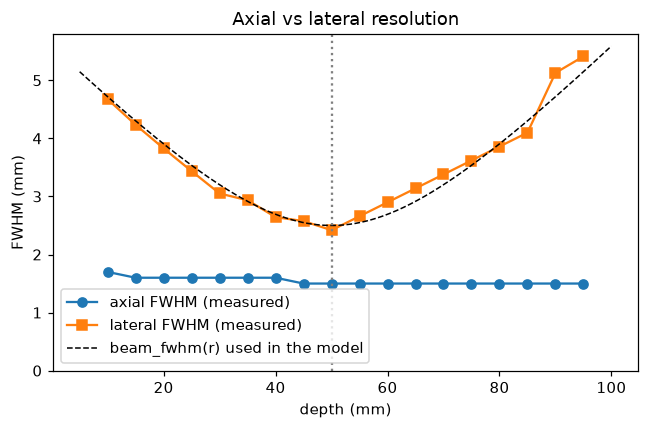

axial FWHM ~ 1.54 mm everywhere; lateral FWHM from 2.4 mm (focus) to 5.4 mm


In [6]:
def fwhm(profile, step):
    p = profile / profile.max()
    above = np.where(p >= 0.5)[0]
    return (above[-1] - above[0] + 1) * step


depths = np.arange(10, 96, 5.0)
ax_mm, lat_mm = [], []
i0 = len(th) // 2                                    # the central scan line
for d in depths:
    imp = np.zeros((len(th), len(r))); imp[i0, int(round(d / dr))] = 1.0
    P = form_image(imp)
    j = np.argmax(P[i0])
    ax_mm.append(fwhm(P[i0, :], dr))                 # along range
    lat_mm.append(fwhm(P[:, j], dth) * r[j])         # across lines, angle -> mm

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(depths, ax_mm, "o-", label="axial FWHM (measured)")
ax.plot(depths, lat_mm, "s-", label="lateral FWHM (measured)")
ax.plot(rr, beam_fwhm(rr), "k--", lw=1, label="beam_fwhm(r) used in the model")
ax.axvline(FOCUS, ls=":", color="gray")
ax.set_xlabel("depth (mm)"); ax.set_ylabel("FWHM (mm)"); ax.set_ylim(0, None); ax.legend()
ax.set_title("Axial vs lateral resolution")
plt.tight_layout(); plt.show()
print(f"axial FWHM ~ {np.mean(ax_mm):.2f} mm everywhere; lateral FWHM from {min(lat_mm):.1f} mm (focus) to {max(lat_mm):.1f} mm")

## Takeaways

- A B-mode image is $J = I * H$: the true reflectivity convolved with the system's point spread function.
- **Axial** resolution (along the beam) is set by the pulse length and is the same at every depth. **Lateral**
  resolution (across beams) is set by the beamwidth, is usually the worse of the two, and changes with depth:
  best at the focus, worse on either side.
- The teardrop comes from the **swept, ringing beam**: the pulse rings (a tail that trails deeper), and the beam
  is indexed by angle, so the same physical beamwidth covers fewer scan lines at greater range. Scan conversion then
  rotates and fans the kernel with the scan angle.
- Convolution (and therefore deconvolution) is cleanest in acquisition coordinates $(r,\theta)$. In display
  coordinates the PSF is **shift-variant**, so sharpening a displayed ultrasound image with one fixed deconvolution
  kernel is only approximately right.
- Compare with earlier weeks: the *kernel-defines-the-blur* idea from filtering, resolution and SNR trade-offs, and
  deconvolution as the attempt to undo $H$ when it is known.

**Try it:** move `FOCUS` to 30 mm, shrink `W0`, lengthen `TAIL`, or widen the sector (`HALF_ANGLE`), and watch
how the teardrops change.